# Kohonen Self-Organizing Map (SOM)

In [20]:
!pip install minisom


In [21]:
from minisom import MiniSom
import numpy as np
from sklearn.datasets import load_digits
from sklearn.preprocessing import scale
import matplotlib.pyplot as plt

In [22]:
# Load dataset
digits= load_digits()
# digits

In [23]:
data = digits.data
labels = digits.target

In [24]:
data.shape, data

((1797, 64),
 array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]]))

In [25]:
labels.shape, labels

((1797,), array([0, 1, 2, ..., 8, 9, 8]))

In [26]:
# Normalization
data_norm = scale(data)
data[0], data_norm[0]

(array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
        15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
        12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
         0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
        10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.]),
 array([ 0.        , -0.33501649, -0.04308102,  0.27407152, -0.66447751,
        -0.84412939, -0.40972392, -0.12502292, -0.05907756, -0.62400926,
         0.4829745 ,  0.75962245, -0.05842586,  1.12772113,  0.87958306,
        -0.13043338, -0.04462507,  0.11144272,  0.89588044, -0.86066632,
        -1.14964846,  0.51547187,  1.90596347, -0.11422184, -0.03337973,
         0.48648928,  0.46988512, -1.49990136, -1.61406277,  0.07639777,
         1.54181413, -0.04723238,  0.        ,  0.76465553,  0.05263019,
        -1.44763006, -1.73666443,  0.04361588,  1.43955804,  0.        ,
        -0.06134367,  0.8105536 ,  0.63011714, -1.1224

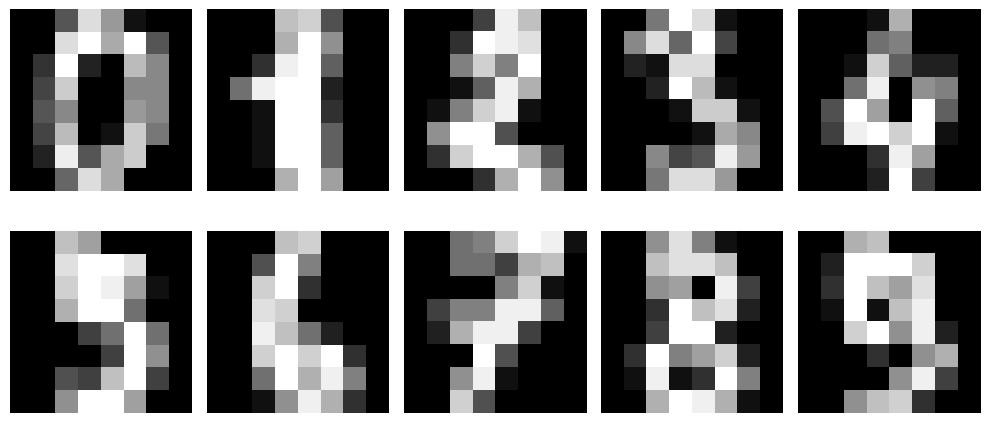

In [27]:
plt.figure(figsize=(10, 5))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(data[i].reshape(8, 8), cmap='gray')
  plt.axis('off')

plt.tight_layout()
plt.show()

In [28]:
# SOM
som = MiniSom(
    x=30,
    y=30,
    input_len=data.shape[1],
    sigma=4.0,
    learning_rate=0.5)

som.random_weights_init(data_norm)
som.train_random(data_norm, 1000, verbose=True)

 [ 1000 / 1000 ] 100% - 0:00:00 left 
 quantization error: 4.313484190722923


In [29]:
mappings = som.win_map(data_norm)

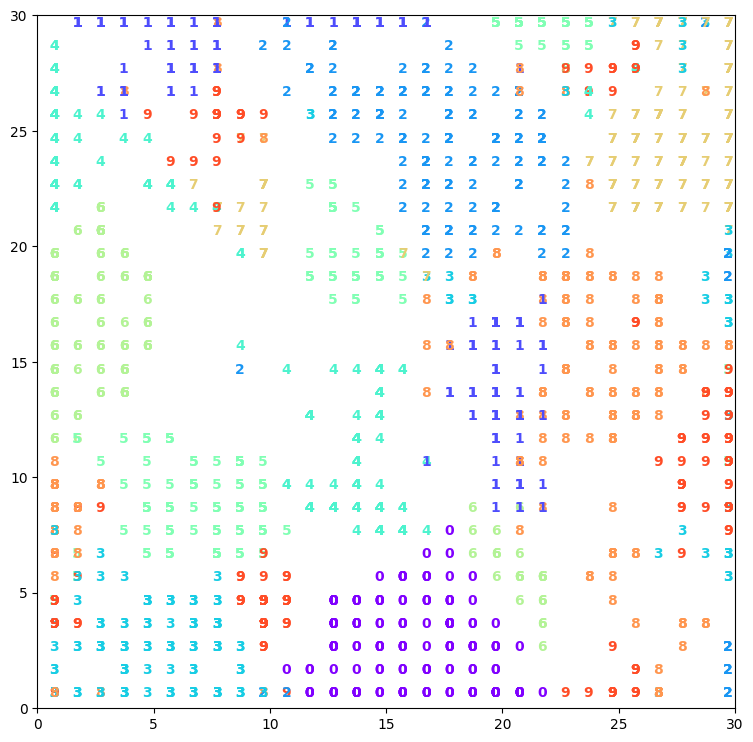

In [30]:
# Visualization
plt.figure(figsize=(9, 9))
image=0

for x, y in zip(data_norm, labels):
  w = som.winner(x)
  # print(y, w)

  plt.text(w[0]+0.5, w[1]+0.5, str(y),
           color=plt.cm.rainbow(y/10),
           fontdict={'weight': 'bold', 'size': 10})
  image+=1

plt.axis([0, som.get_weights().shape[0], 0, som.get_weights().shape[1]])
plt.show()



In [31]:

from collections import Counter

# Find the winning neuron for every image
winners = [som.winner(x) for x in data_norm]

# Count images assigned to each neuron
counts = Counter(winners)

print("Total images:", len(data_norm))
print("Total SOM neurons:", 30 * 30)
print("Neurons with images:", len(counts))
print("Empty neurons:", 900 - len(counts))
print("Most images assigned to one neuron:", max(counts.values()))
print("Total assignments:", sum(counts.values()))

Total images: 1797
Total SOM neurons: 900
Neurons with images: 582
Empty neurons: 318
Most images assigned to one neuron: 19
Total assignments: 1797
